# Sumativa 2 — Base de resultados y simulación Monte Carlo

**Equipo:** Hernán Saavedra, Lenin Salas y Rodrigo Gómez.  
**Responsable de este bloque:** Hernán Saavedra.

## Objetivo

Preparar resultados de referencia de la Sumativa 1 y simular escenarios
de salida utilizando parámetros estimados en ese análisis.

Se utiliza el dataset IBM HR original completo, sin faltantes artificiales.
Los datos son sintéticos: los resultados no representan predicciones
para una empresa real ni permiten establecer causalidad.

In [10]:
from pathlib import Path
import hashlib
import json
import sys

import numpy as np
import pandas as pd
import scipy
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

# Buscar la raíz desde cualquier carpeta dentro del repositorio.
nombre_csv = "WA_Fn-UseC_-HR-Employee-Attrition.csv"
carpeta_actual = Path.cwd().resolve()

raiz = next(
    (
        carpeta
        for carpeta in [carpeta_actual, *carpeta_actual.parents]
        if (carpeta / "datos" / nombre_csv).is_file()
    ),
    None
)

if raiz is None:
    raise FileNotFoundError(
        "No se encontró el dataset en la carpeta datos del repositorio."
    )

ruta_datos = raiz / "datos" / nombre_csv
ruta_notebook_s1 = raiz / "S1" / "Sumativa1_IBM_HR.ipynb"

if not ruta_notebook_s1.is_file():
    raise FileNotFoundError(
        f"No se encontró el notebook de referencia: {ruta_notebook_s1}"
    )

carpeta_figuras = raiz / "S2" / "figuras"
carpeta_resultados = raiz / "S2" / "resultados"

carpeta_figuras.mkdir(parents=True, exist_ok=True)
carpeta_resultados.mkdir(parents=True, exist_ok=True)

# Cargar el original y conservar una copia para el análisis.
original = pd.read_csv(ruta_datos)
df = original.copy(deep=True)

# Configuración de reproducibilidad.
SEMILLA = 42
N_ITERACIONES = 10_000

# Se crearán generadores independientes para cada procedimiento.
# Esto evita depender del orden de ejecución de otros bloques.
sns.set_theme(style="whitegrid")

huella_csv = hashlib.sha256(ruta_datos.read_bytes()).hexdigest()
huella_notebook_s1 = hashlib.sha256(
    ruta_notebook_s1.read_bytes()
).hexdigest()

versiones = {
    "Python": sys.version.split()[0],
    "pandas": pd.__version__,
    "NumPy": np.__version__,
    "SciPy": scipy.__version__,
    "Matplotlib": matplotlib.__version__,
    "seaborn": sns.__version__
}

print("Raíz del repositorio:", raiz)
print(f"Dataset: {df.shape[0]} registros y {df.shape[1]} columnas")
print("Faltantes:", int(df.isna().sum().sum()))
print("Filas duplicadas:", int(df.duplicated().sum()))
print("Semilla base:", SEMILLA)
print("Iteraciones previstas:", N_ITERACIONES)
print("SHA-256 del CSV:", huella_csv)

print("\nVersiones del entorno")
for biblioteca, version in versiones.items():
    print(f"{biblioteca}: {version}")

display(df.head())

Raíz del repositorio: C:\Users\Papá\Documents\2026\Magister\estadisticaComputacional
Dataset: 1470 registros y 35 columnas
Faltantes: 0
Filas duplicadas: 0
Semilla base: 42
Iteraciones previstas: 10000
SHA-256 del CSV: a5c31e38bd7fafc9bc333884eb181b06b41b8e5e488e8f7ccb27199fb3be7659

Versiones del entorno
Python: 3.11.9
pandas: 3.0.6
NumPy: 2.4.6
SciPy: 1.17.1
Matplotlib: 3.11.2
seaborn: 0.13.2


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


## 1. Resultados de referencia de la Sumativa 1

Se reproducen las medias y los intervalos t del 95 % para ingreso mensual,
edad y antigüedad, utilizando el mismo dataset completo y procedimiento
de la Sumativa 1.

Los resultados se exportan sin redondear. El formato con coma decimal
se aplica únicamente a la presentación.

In [11]:
variables_medias = ["MonthlyIncome", "Age", "YearsAtCompany"]

referencias_medias = []

for variable in variables_medias:
    valores = df[variable].dropna()
    n = len(valores)
    media = valores.mean()
    desviacion = valores.std(ddof=1)
    error_estandar = stats.sem(valores)

    inferior, superior = stats.t.interval(
        confidence=0.95,
        df=n - 1,
        loc=media,
        scale=error_estandar
    )

    referencias_medias.append({
        "variable": variable,
        "n": n,
        "media": media,
        "desviacion_estandar": desviacion,
        "error_estandar": error_estandar,
        "ic95_inferior": inferior,
        "ic95_superior": superior,
        "metodo": "t de Student"
    })

referencias_medias = pd.DataFrame(referencias_medias)

# Mostrar una copia formateada.
presentacion = referencias_medias.copy()

columnas_decimales = [
    "media",
    "desviacion_estandar",
    "error_estandar",
    "ic95_inferior",
    "ic95_superior"
]

for columna in columnas_decimales:
    presentacion[columna] = presentacion[columna].map(
        lambda valor: f"{valor:.2f}".replace(".", ",")
    )

display(presentacion)

# Exportar valores numéricos con precisión suficiente para recuperarlos.
ruta_medias = carpeta_resultados / "S1_referencia_medias.csv"

referencias_medias.to_csv(
    ruta_medias,
    index=False,
    encoding="utf-8-sig",
    float_format="%.17g"
)

print("Referencia guardada:", ruta_medias)

,variable,n,media,desviacion_estandar,error_estandar,ic95_inferior,ic95_superior,metodo
0,MonthlyIncome,1470,"6502,93","4707,96","122,79","6262,06","6743,80",t de Student
1,Age,1470,"36,92","9,14","0,24","36,46","37,39",t de Student
2,YearsAtCompany,1470,"7,01","6,13","0,16","6,69","7,32",t de Student


Referencia guardada: C:\Users\Papá\Documents\2026\Magister\estadisticaComputacional\S2\resultados\S1_referencia_medias.csv


## 2. Correlaciones de referencia de la Sumativa 1

Se reproducen cuatro correlaciones de Spearman previamente examinadas:
ingreso con experiencia, edad con experiencia, antigüedad con experiencia
y distancia con ingreso.

La selección incluye asociaciones positivas y una cercana a cero.
Su estabilidad se evaluará posteriormente mediante remuestreo de filas
completas, conservando el emparejamiento de las variables.

In [12]:
pares_correlaciones = [
    ("MonthlyIncome", "TotalWorkingYears"),
    ("Age", "TotalWorkingYears"),
    ("YearsAtCompany", "TotalWorkingYears"),
    ("DistanceFromHome", "MonthlyIncome")
]

filas_correlaciones = []

for variable_x, variable_y in pares_correlaciones:
    pares_validos = df[[variable_x, variable_y]].dropna()

    rho = pares_validos[variable_x].corr(
        pares_validos[variable_y],
        method="spearman"
    )

    filas_correlaciones.append({
        "variable_x": variable_x,
        "variable_y": variable_y,
        "n": len(pares_validos),
        "rho_spearman": rho
    })

referencias_correlaciones = pd.DataFrame(filas_correlaciones)

# Formatear únicamente la presentación.
presentacion_correlaciones = referencias_correlaciones.copy()

presentacion_correlaciones["rho_spearman"] = (
    presentacion_correlaciones["rho_spearman"].map(
        lambda valor: f"{valor:.4f}".replace(".", ",")
    )
)

display(presentacion_correlaciones)

ruta_correlaciones = (
    carpeta_resultados / "S1_referencia_correlaciones.csv"
)

referencias_correlaciones.to_csv(
    ruta_correlaciones,
    index=False,
    encoding="utf-8-sig",
    float_format="%.17g"
)

print("Referencia guardada:", ruta_correlaciones)

,variable_x,variable_y,n,rho_spearman
0,MonthlyIncome,TotalWorkingYears,1470,"0,7100"
1,Age,TotalWorkingYears,1470,"0,6569"
2,YearsAtCompany,TotalWorkingYears,1470,"0,5942"
3,DistanceFromHome,MonthlyIncome,1470,"0,0025"


Referencia guardada: C:\Users\Papá\Documents\2026\Magister\estadisticaComputacional\S2\resultados\S1_referencia_correlaciones.csv


## 3. Pruebas y proporciones de referencia de la Sumativa 1

Se reproducen chi-cuadrado sin corrección de continuidad para horas extra
y salida, y t de Welch bilateral para ingreso mensual según salida.

La diferencia de ingresos se define como permanece menos sale.
También se conservan los tamaños y las proporciones de salida por horas
extra como entradas para la simulación Monte Carlo.

In [13]:
# Chi-cuadrado: horas extra y salida.
contingencia = pd.crosstab(
    df["OverTime"], df["Attrition"]
).reindex(index=["No", "Yes"], columns=["No", "Yes"])

chi2, p_chi2, gl_chi2, esperadas = stats.chi2_contingency(
    contingencia,
    correction=False
)

v_cramer = np.sqrt(chi2 / contingencia.to_numpy().sum())

# Welch: ingreso de quienes permanecen menos ingreso de quienes salen.
ingreso_no = df.loc[
    df["Attrition"].eq("No"), "MonthlyIncome"
].dropna()

ingreso_si = df.loc[
    df["Attrition"].eq("Yes"), "MonthlyIncome"
].dropna()

welch = stats.ttest_ind(
    ingreso_no,
    ingreso_si,
    equal_var=False,
    alternative="two-sided"
)

ic_diferencia = welch.confidence_interval(confidence_level=0.95)

referencias_pruebas = pd.DataFrame([
    {
        "prueba": "Chi-cuadrado sin correccion",
        "estadistico": chi2,
        "gl": gl_chi2,
        "valor_p": p_chi2,
        "v_cramer": v_cramer,
        "esperada_minima": esperadas.min(),
        "diferencia_medias": np.nan,
        "ic95_inferior": np.nan,
        "ic95_superior": np.nan
    },
    {
        "prueba": "Welch bilateral permanece menos sale",
        "estadistico": welch.statistic,
        "gl": welch.df,
        "valor_p": welch.pvalue,
        "v_cramer": np.nan,
        "esperada_minima": np.nan,
        "diferencia_medias": ingreso_no.mean() - ingreso_si.mean(),
        "ic95_inferior": ic_diferencia.low,
        "ic95_superior": ic_diferencia.high
    }
])

# Entradas de Monte Carlo: tamaños y proporciones observadas por grupo.
referencias_grupos = pd.DataFrame({
    "n": contingencia.sum(axis=1),
    "salidas": contingencia["Yes"]
})

referencias_grupos["proporcion_salida"] = (
    referencias_grupos["salidas"] / referencias_grupos["n"]
)

referencias_grupos.index.name = "OverTime"
referencias_grupos = referencias_grupos.reset_index()

# Exportar valores sin redondearlos.
referencias_pruebas.to_csv(
    carpeta_resultados / "S1_referencia_pruebas.csv",
    index=False,
    encoding="utf-8-sig",
    float_format="%.17g"
)

referencias_grupos.to_csv(
    carpeta_resultados / "S1_referencia_grupos.csv",
    index=False,
    encoding="utf-8-sig",
    float_format="%.17g"
)

print(f"Chi-cuadrado: {chi2:.4f}; p = {p_chi2:.6g}")
print(f"V de Cramér: {v_cramer:.4f}")
print(f"Welch: t = {welch.statistic:.4f}; p = {welch.pvalue:.6g}")
print(
    "Diferencia media:",
    f"{ingreso_no.mean() - ingreso_si.mean():.2f}"
)
print(
    "IC del 95 %:",
    f"[{ic_diferencia.low:.2f}; {ic_diferencia.high:.2f}]"
)

display(referencias_grupos)

Chi-cuadrado: 89.0439; p = 3.86152e-21
V de Cramér: 0.2461
Welch: t = 7.4826; p = 4.43359e-13
Diferencia media: 2045.65
IC del 95 %: [1508.24; 2583.05]


,OverTime,n,salidas,proporcion_salida
0,No,1054,110,0.104364
1,Yes,416,127,0.305288


## 4. Registro de trazabilidad

Se registran las rutas, huellas SHA-256, versiones del entorno y archivos
de referencia. Las huellas permiten detectar cambios en el dataset
o en el notebook de S1.

Los cálculos anteriores reproducen los procedimientos de S1; su coincidencia
numérica es una comprobación de referencia, no una validación de robustez.
Esta última se realizará mediante bootstrap, permutación y sensibilidad.

In [14]:
archivos_referencia = [
    "S1_referencia_medias.csv",
    "S1_referencia_correlaciones.csv",
    "S1_referencia_pruebas.csv",
    "S1_referencia_grupos.csv"
]

registro = {
    "equipo": [
        "Hernán Saavedra",
        "Lenin Salas",
        "Rodrigo Gómez"
    ],
    "dataset": {
        "ruta": ruta_datos.relative_to(raiz).as_posix(),
        "sha256": huella_csv,
        "registros": len(df),
        "columnas": len(df.columns)
    },
    "notebook_s1": {
        "ruta": ruta_notebook_s1.relative_to(raiz).as_posix(),
        "sha256": huella_notebook_s1
    },
    "versiones": versiones,
    "semilla_base": SEMILLA,
    "iteraciones_previstas": N_ITERACIONES,
    "referencias": [
        {
            "ruta": (carpeta_resultados / nombre)
                .relative_to(raiz).as_posix(),
            "sha256": hashlib.sha256(
                (carpeta_resultados / nombre).read_bytes()
            ).hexdigest()
        }
        for nombre in archivos_referencia
    ]
}

ruta_registro = carpeta_resultados / "S1_trazabilidad.json"

ruta_registro.write_text(
    json.dumps(registro, ensure_ascii=False, indent=2),
    encoding="utf-8"
)

print("Registro creado:", ruta_registro)

for referencia in registro["referencias"]:
    print(referencia["ruta"])

Registro creado: C:\Users\Papá\Documents\2026\Magister\estadisticaComputacional\S2\resultados\S1_trazabilidad.json
S2/resultados/S1_referencia_medias.csv
S2/resultados/S1_referencia_correlaciones.csv
S2/resultados/S1_referencia_pruebas.csv
S2/resultados/S1_referencia_grupos.csv


## 5. Diseño de la simulación Monte Carlo

Se simula el número de salidas en dos grupos hipotéticos con los mismos
tamaños y proporciones observadas en la Sumativa 1:

- Sin horas extra: 1.054 empleados y 110 salidas observadas.
- Con horas extra: 416 empleados y 127 salidas observadas.

En cada iteración se genera un conteo binomial por grupo. Se supone
que los empleados tienen una probabilidad de salida constante dentro
de cada grupo y que las salidas son independientes, también entre grupos.

Se mantienen fijos los parámetros estimados. La simulación representa
variabilidad del escenario condicionado a esos parámetros; no incorpora
todavía la incertidumbre de su estimación.

El escenario no tiene un horizonte temporal definido y no representa
una predicción para una empresa real. Tampoco estima el efecto causal
de modificar las horas extra.

In [15]:
# Leer las entradas exportadas desde nuestros resultados de S1.
entradas_mc = pd.read_csv(
    carpeta_resultados / "S1_referencia_grupos.csv",
    encoding="utf-8-sig",
    float_precision="round_trip"
).set_index("OverTime")

n_sin_extra = int(entradas_mc.loc["No", "n"])
n_con_extra = int(entradas_mc.loc["Yes", "n"])

p_sin_extra = float(entradas_mc.loc["No", "proporcion_salida"])
p_con_extra = float(entradas_mc.loc["Yes", "proporcion_salida"])

# Generador exclusivo para este procedimiento.
rng_mc = np.random.default_rng(
    np.random.SeedSequence([SEMILLA, 1])
)

salidas_sin_extra = rng_mc.binomial(
    n=n_sin_extra,
    p=p_sin_extra,
    size=N_ITERACIONES
)

salidas_con_extra = rng_mc.binomial(
    n=n_con_extra,
    p=p_con_extra,
    size=N_ITERACIONES
)

simulaciones_mc = pd.DataFrame({
    "iteracion": np.arange(1, N_ITERACIONES + 1),
    "salidas_sin_extra": salidas_sin_extra,
    "salidas_con_extra": salidas_con_extra
})

simulaciones_mc["salidas_totales"] = (
    simulaciones_mc["salidas_sin_extra"]
    + simulaciones_mc["salidas_con_extra"]
)

# Comparar porcentajes porque los grupos tienen tamaños diferentes.
simulaciones_mc["diferencia_pp"] = 100 * (
    simulaciones_mc["salidas_con_extra"] / n_con_extra
    - simulaciones_mc["salidas_sin_extra"] / n_sin_extra
)

esperanza_total = (
    n_sin_extra * p_sin_extra
    + n_con_extra * p_con_extra
)

diferencia_teorica_pp = 100 * (p_con_extra - p_sin_extra)

print("Iteraciones:", len(simulaciones_mc))
print(f"Salidas totales esperadas por el modelo: {esperanza_total:.2f}")
print(
    "Promedio de salidas totales simuladas:",
    f"{simulaciones_mc['salidas_totales'].mean():.2f}"
)
print(
    "Diferencia de proporciones usada como entrada:",
    f"{diferencia_teorica_pp:.2f} puntos porcentuales"
)
print(
    "Diferencia promedio simulada:",
    f"{simulaciones_mc['diferencia_pp'].mean():.2f} puntos porcentuales"
)

display(simulaciones_mc.head())

Iteraciones: 10000
Salidas totales esperadas por el modelo: 237.00
Promedio de salidas totales simuladas: 236.90
Diferencia de proporciones usada como entrada: 20.09 puntos porcentuales
Diferencia promedio simulada: 20.08 puntos porcentuales


,iteracion,salidas_sin_extra,salidas_con_extra,salidas_totales,diferencia_pp
0,1,117,105,222,14.139815
1,2,112,123,235,18.941122
2,3,110,135,245,22.015490
3,4,108,130,238,21.003321
4,5,120,130,250,19.864801


## 6. Convergencia y error Monte Carlo

Se examina el promedio acumulado de salidas y su error estándar
Monte Carlo al aumentar el número de iteraciones.

El error Monte Carlo mide la precisión del promedio simulado condicionado
al modelo. No representa la incertidumbre de los parámetros estimados
en S1 ni la dispersión de los escenarios individuales.

Como comprobación, se compara el promedio simulado con la esperanza
analítica de 237 salidas.

,iteraciones,promedio_salidas,desviacion_escenarios,error_estandar_mc,margen_mc_95,diferencia_con_esperanza
0,100,"236,0700","15,3342","1,5334","3,0055","-0,9300"
1,500,"236,2120","14,1961","0,6349","1,2443","-0,7880"
2,1000,"236,7690","14,0388","0,4439","0,8701","-0,2310"
3,2000,"236,7535","13,9104","0,3110","0,6097","-0,2465"
4,5000,"236,8092","13,6215","0,1926","0,3776","-0,1908"
5,10000,"236,9038","13,7430","0,1374","0,2694","-0,0962"


Margen Monte Carlo final del 95 %: ±0.2694 salidas
Cumple la precisión objetivo de ±0,5 salidas: True


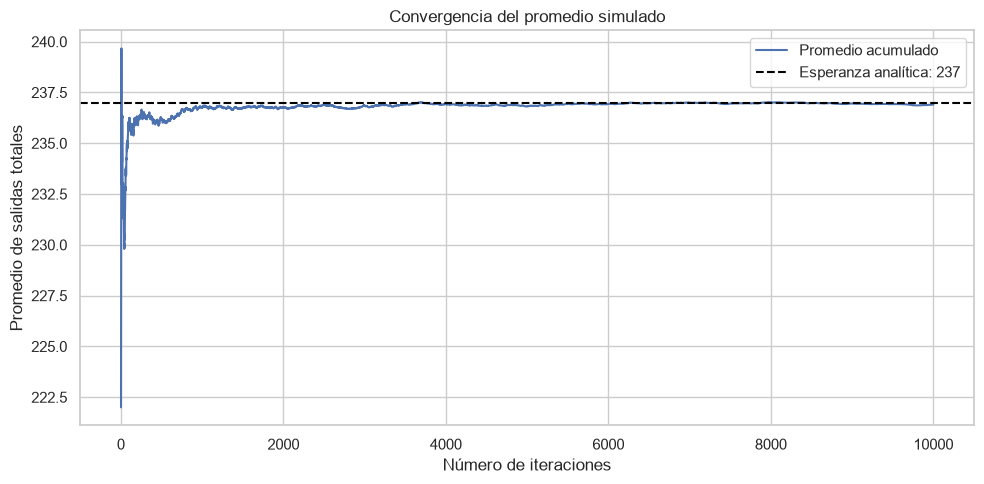

In [16]:
totales = simulaciones_mc["salidas_totales"].to_numpy()

puntos_revision = [100, 500, 1_000, 2_000, 5_000, 10_000]
filas_convergencia = []

for cantidad in puntos_revision:
    muestra = totales[:cantidad]

    promedio = muestra.mean()
    desviacion = muestra.std(ddof=1)
    error_mc = desviacion / np.sqrt(cantidad)

    filas_convergencia.append({
        "iteraciones": cantidad,
        "promedio_salidas": promedio,
        "desviacion_escenarios": desviacion,
        "error_estandar_mc": error_mc,
        "margen_mc_95": 1.96 * error_mc,
        "diferencia_con_esperanza": promedio - esperanza_total
    })

convergencia_mc = pd.DataFrame(filas_convergencia)

presentacion = convergencia_mc.copy()

for columna in presentacion.columns:
    if columna != "iteraciones":
        presentacion[columna] = presentacion[columna].map(
            lambda valor: f"{valor:.4f}".replace(".", ",")
        )

display(presentacion)

# Precisión objetivo para el promedio: margen MC de ±0,5 salidas.
tolerancia_mc = 0.5
margen_final = convergencia_mc.iloc[-1]["margen_mc_95"]

print(
    "Margen Monte Carlo final del 95 %:",
    f"±{margen_final:.4f} salidas"
)
print(
    "Cumple la precisión objetivo de ±0,5 salidas:",
    bool(margen_final <= tolerancia_mc)
)

# Promedio acumulado.
iteraciones = np.arange(1, len(totales) + 1)
promedio_acumulado = np.cumsum(totales) / iteraciones

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    iteraciones,
    promedio_acumulado,
    label="Promedio acumulado"
)

ax.axhline(
    esperanza_total,
    color="black",
    linestyle="--",
    label=f"Esperanza analítica: {esperanza_total:.0f}"
)

ax.set_xlabel("Número de iteraciones")
ax.set_ylabel("Promedio de salidas totales")
ax.set_title("Convergencia del promedio simulado")
ax.legend()

fig.tight_layout()
fig.savefig(
    carpeta_figuras / "hernan_mc_convergencia.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

convergencia_mc.to_csv(
    carpeta_resultados / "hernan_mc_convergencia.csv",
    index=False,
    encoding="utf-8-sig",
    float_format="%.17g"
)

### Interpretación de la convergencia

Con 10.000 iteraciones, el promedio simulado es de 236,9038 salidas,
frente a una esperanza analítica de 237. La diferencia es de −0,0962
salidas y la curva del promedio acumulado muestra estabilización.

El error estándar Monte Carlo es 0,1374 y el margen aproximado del
95 % es ±0,2694 salidas, inferior a la tolerancia definida de ±0,5.
Por tanto, la simulación alcanza la precisión computacional buscada
para estimar el promedio bajo este modelo.

La desviación estándar de los escenarios es 13,7430 salidas:
describe la variabilidad entre escenarios individuales y no debe
confundirse con el error estándar del promedio simulado.

Esta comprobación respalda la precisión numérica de la simulación,
pero no valida los supuestos del modelo ni incorpora la incertidumbre
de las proporciones estimadas en S1.

## 7. Distribución de los escenarios simulados

Se calculan los percentiles 2,5 y 97,5 del número total de salidas
y de la diferencia de porcentajes entre grupos.

Estos límites describen el rango central aproximado del 95 % de los
escenarios bajo el modelo con parámetros fijos. No son intervalos
de confianza para los parámetros ni intervalos bootstrap.

La distribución simulada de la diferencia tampoco es un test de
permutación: se genera usando las proporciones observadas,
sin imponer una hipótesis nula de igualdad.

,variable,media,desviacion_estandar,percentil_2_5,mediana,percentil_97_5
0,salidas_totales,"236,90","13,74","210,00","237,00","264,00"
1,diferencia_pp,"20,08","2,44","15,28","20,09","24,84"


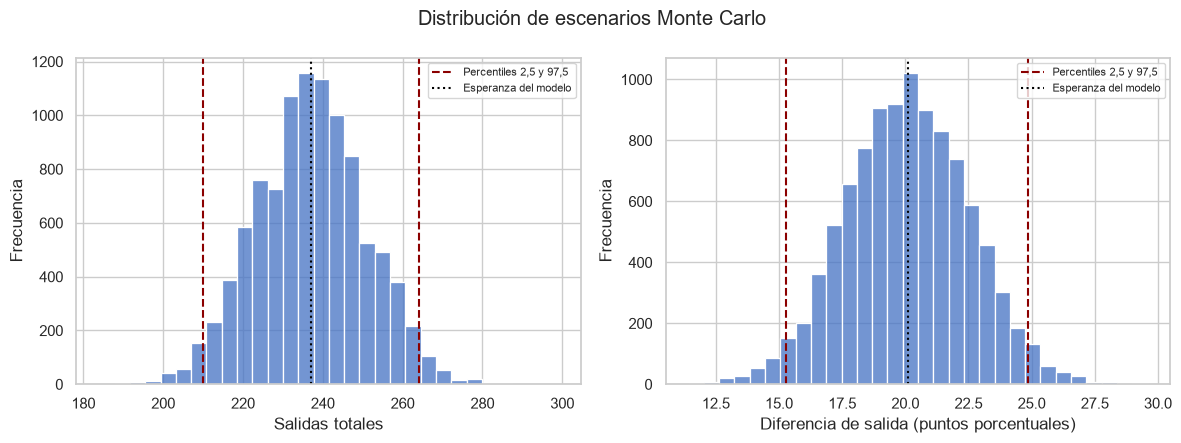

In [17]:
variables_escenarios = {
    "salidas_totales": "Salidas totales",
    "diferencia_pp": "Diferencia de salida (puntos porcentuales)"
}

filas_resumen = []

for variable, etiqueta in variables_escenarios.items():
    valores = simulaciones_mc[variable]

    filas_resumen.append({
        "variable": variable,
        "media": valores.mean(),
        "desviacion_estandar": valores.std(ddof=1),
        "percentil_2_5": valores.quantile(0.025),
        "mediana": valores.median(),
        "percentil_97_5": valores.quantile(0.975)
    })

resumen_mc = pd.DataFrame(filas_resumen)

presentacion = resumen_mc.copy()

for columna in presentacion.columns:
    if columna != "variable":
        presentacion[columna] = presentacion[columna].map(
            lambda valor: f"{valor:.2f}".replace(".", ",")
        )

display(presentacion)

# Visualizar ambas distribuciones.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, (variable, etiqueta) in zip(
    axes, variables_escenarios.items()
):
    valores = simulaciones_mc[variable]
    inferior, superior = valores.quantile([0.025, 0.975])

    sns.histplot(
        valores,
        bins=30,
        color="#4472C4",
        ax=ax
    )

    ax.axvline(
        inferior,
        color="darkred",
        linestyle="--",
        label="Percentiles 2,5 y 97,5"
    )
    ax.axvline(
        superior,
        color="darkred",
        linestyle="--"
    )

    referencia = (
        esperanza_total
        if variable == "salidas_totales"
        else diferencia_teorica_pp
    )

    ax.axvline(
        referencia,
        color="black",
        linestyle=":",
        label="Esperanza del modelo"
    )

    ax.set_xlabel(etiqueta)
    ax.set_ylabel("Frecuencia")
    ax.legend(fontsize=8)

fig.suptitle("Distribución de escenarios Monte Carlo")
fig.tight_layout()

fig.savefig(
    carpeta_figuras / "hernan_mc_distribuciones.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Guardar simulaciones completas y resumen.
simulaciones_mc.to_csv(
    carpeta_resultados / "hernan_mc_simulaciones.csv",
    index=False,
    encoding="utf-8-sig",
    float_format="%.17g"
)

resumen_mc.to_csv(
    carpeta_resultados / "hernan_mc_resumen.csv",
    index=False,
    encoding="utf-8-sig",
    float_format="%.17g"
)

### Interpretación de los escenarios

En las 10.000 simulaciones, el promedio de salidas totales fue 236,90
y la mediana 237. Los percentiles 2,5 y 97,5 fueron 210 y 264:
estos límites describen el rango central aproximado del 95 % de
los escenarios generados bajo el modelo.

La diferencia de porcentajes de salida entre quienes realizan horas
extra y quienes no las realizan tuvo una media simulada de 20,08
puntos porcentuales. Su rango central aproximado del 95 % se situó
entre 15,28 y 24,84 puntos porcentuales.

Estos resultados describen la variabilidad de escenarios hipotéticos
con tamaños y probabilidades fijos, tomados de S1. No constituyen
intervalos de confianza de los parámetros, una nueva prueba de
hipótesis ni una predicción anual.

La diferencia positiva refleja las probabilidades distintas utilizadas
como entradas. No demuestra un efecto causal de las horas extra.
La incertidumbre de esas probabilidades y posibles dependencias
entre empleados no están incorporadas en este modelo.

In [18]:
# Repetir la simulación con la misma semilla y el mismo orden.
rng_verificacion = np.random.default_rng(
    np.random.SeedSequence([SEMILLA, 1])
)

verificacion_sin_extra = rng_verificacion.binomial(
    n_sin_extra, p_sin_extra, size=N_ITERACIONES
)
verificacion_con_extra = rng_verificacion.binomial(
    n_con_extra, p_con_extra, size=N_ITERACIONES
)

assert np.array_equal(salidas_sin_extra, verificacion_sin_extra)
assert np.array_equal(salidas_con_extra, verificacion_con_extra)

# Comprobar que el archivo original de datos no fue modificado.
assert hashlib.sha256(ruta_datos.read_bytes()).hexdigest() == huella_csv

print("Reproducibilidad: correcta.")
print("Archivo original de datos: sin modificaciones.")
print(f"Iteraciones realizadas: {N_ITERACIONES:,}")

Reproducibilidad: correcta.
Archivo original de datos: sin modificaciones.
Iteraciones realizadas: 10,000
